# 3 · Your own data

Our 300 tiles came from somewhere. Each label was drawn on one Sentinel-2 picture, and Sentinel-2 pictures are published in public catalogs anyone can search. Fetching the imagery ourselves means any place and any date, and more than one picture of the same place.

This notebook needs an internet connection.

In [1]:
from pathlib import Path

from huggingface_hub import snapshot_download

import geosave_engine as gs

root = Path(snapshot_download("fatmur/dynamicworld-300", repo_type="dataset", local_dir="data/dynamic_world"))

images = sorted((root / "train/images").glob("*.tif"))
labels = sorted((root / "train/labels").glob("*.tif"))
label = gs.open_raster(labels[0])

anchor = label.gs.anchor
anchor.format("lat {lat:.2f}, lon {lon:.2f}, {start:%d %B %Y}, {width:g} m across at {res:g} m")

Fetching 603 files:   0%|          | 0/603 [00:00<?, ?it/s]

'lat 20.13, lon -100.22, 30 January 2019, 5100 m across at 10 m'

## Where and when

An **anchor** is what a search needs from the label: its grid, which says where its pixels lie on Earth and how big they are, and its date. Catalogs that follow the [STAC](https://stacspec.org) standard list pictures by place and time, so the anchor is enough to ask one. Microsoft's Planetary Computer publishes every Sentinel-2 picture.

In [2]:
client = gs.stac.StacClient.open("planetary_computer")
source = client.source("sentinel-2-l2a")

source.search(anchor)[["id", "datetime", "eo:cloud_cover"]]

,id,datetime,eo:cloud_cover
0,S2A_MSIL2A_20190130T171541_R112_T14QLH_2020100...,2019-01-30 17:15:41.024000+00:00,0.058349


## Load the picture

One picture matches: the one the label was drawn on. `load` reads it onto the label's grid, so its pixels line up with the label's without resampling by hand.

The catalog stores reflectance as whole numbers times 10,000 but does not say so. We state the stored type, the value that marks no measurement, and the scale ourselves; `write_rgb` names the bands a colour picture draws.

:Layout
   .RGB.I   :RGB   [x,y]   (R,G,B)
   .Image.I :Image   [x,y]   (value)
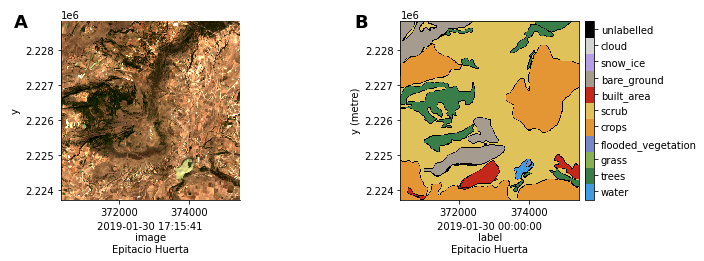

In [3]:
bands = ["B02", "B03", "B04", "B08"]
source = source.set_config(bands=[*bands, "SCL"], dtype="uint16", nodata=0)

image = source.load(anchor)
image = image.gs.write_packing(1e-4, target=bands).gs.write_rgb(red="B04", green="B03", blue="B02")

gs.stack({"image": image, "label": label}).gs.plot(cols=2)

It is the picture our dataset ships, pixel for pixel:

In [4]:
shipped = gs.open_raster(images[0])

bool((image.B04.values == shipped.B04.values).all())

True

## A month of pictures

One date is one look, and some days are cloudy. Sentinel-2 passes every few days, so a whole month gives several looks at the same place. `set_query` widens the search beyond the label's date and keeps pictures the catalog rates at most 20% cloudy.

`SCL`, the scene classification band we loaded alongside, marks each pixel as clear, cloud, shadow and so on; `scl_valid_mask` keeps the clear ones. The share per date shows how much each look adds.

In [5]:
month = source.set_query(datetime="2019-01", filter="eo:cloud_cover <= 20")

scenes = month.load(anchor).gs.write_packing(1e-4, target=bands)
clear = gs.features.scl_valid_mask(scenes, scl="SCL")

clear.mean(dim=["y", "x"]).to_series()

/home/uwu/Projects/geosave-engine/.venv/lib/python3.12/site-packages/rasterio/warp.py:385: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dest = _reproject(


time
2019-01-05 17:17:09.024    0.997539
2019-01-07 17:07:01.024    0.986282
2019-01-10 17:17:01.024    0.942007
2019-01-17 17:06:31.024    0.996571
2019-01-20 17:16:31.024    0.994387
2019-01-22 17:06:19.024    0.997432
2019-01-25 17:16:09.024    0.998478
2019-01-27 17:05:51.024    0.996894
2019-01-30 17:15:41.024    0.997632
dtype: float64

## One clear picture from many

A **composite** keeps, for every pixel, the median of its clear looks in reflectance: clouds and shadows drop out and the month's typical colour remains. Every picture is read from the catalog here, so this cell takes a minute or two.

:RGB   [x,y]   (R,G,B)
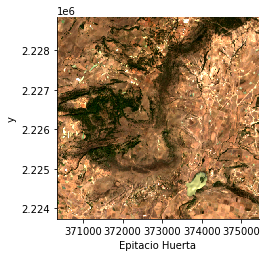

In [6]:
reflectance = scenes[bands].gs.mask_and_scale().where(clear)
composite = reflectance.median("time").compute()

composite = composite.gs.write_rgb(red="B04", green="B03", blue="B02")
composite.gs.plot()

Save it as a Cloud-Optimized GeoTIFF. It keeps its grid and band names, so it opens again beside the label without going back to the catalog.

In [7]:
composite.gs.to_cog("composite.tif", overwrite=True)

(CogFile(/home/uwu/Projects/geosave-engine/examples/composite.tif, bands=['B02', 'B03', 'B04', 'B08'], undated, -),)

## What happened

We took a label's place and date as an anchor, searched a public catalog with it, and loaded the matching picture onto the label's grid: the same pixels our dataset ships. Widening the date to a month gave several looks; the scene classification band kept the clear pixels, and a median turned them into one clear composite, saved for later.

The catalog did not describe its pixels' scale, so we stated it. Catalogs differ, and when one leaves something out, the reader fills it in.

| Next | Question |
| --- | --- |
| 4 · Fitting data to a model | A month of pictures over a whole area is not a model input. How do I cut it into what a model reads? |